# Descriptive & Inferential Statistical Analysis of the Iris Dataset

**Tools:** Python · pandas · SciPy · Matplotlib · Jupyter Notebook · Git/GitHub

## Objective
1. Perform **descriptive** and **inferential** statistical analysis on the Iris dataset.
2. Build **visual analytics** with Matplotlib that communicate the key findings.
3. Document everything as a **reproducible research workflow** (Jupyter Notebook + GitHub).

## Dataset
Fisher's Iris data (1936): 150 flowers, 50 from each of three species (*Iris setosa*, *Iris versicolor*, *Iris virginica*), with four measurements in centimetres: sepal length, sepal width, petal length and petal width.

## Contents
1. Setup
2. Data loading and quality checks
3. Descriptive statistics
4. Visual analytics (Matplotlib)
5. Inferential statistics
6. Key findings
7. Reproducibility and GitHub workflow

## 1. Setup
All libraries are imported in one place, a random seed is fixed, and global plotting options are set so every figure has a consistent look. Figures are saved to `figures/` so they can be reused in reports.

In [1]:
import os
import sys
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from IPython.display import display

%matplotlib inline

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
})

FEATURES = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
LABELS = {
    "sepal_length": "Sepal length (cm)",
    "sepal_width": "Sepal width (cm)",
    "petal_length": "Petal length (cm)",
    "petal_width": "Petal width (cm)",
}
SPECIES = ["setosa", "versicolor", "virginica"]
COLORS = {"setosa": "#1b9e77", "versicolor": "#d95f02", "virginica": "#7570b3"}  # colour-blind friendly
ALPHA = 0.05  # significance level used throughout

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

## 2. Data loading and quality checks
The notebook reads `data/iris.csv`. If the file is missing (for example if only the notebook was downloaded), it is regenerated from the copy of the dataset bundled with scikit-learn, so the notebook always runs end to end.

In [2]:
DATA_PATH = "data/iris.csv"

if not os.path.exists(DATA_PATH):
    from sklearn.datasets import load_iris
    raw = load_iris(as_frame=True)
    frame = raw.frame.copy()
    frame.columns = FEATURES + ["target"]
    frame["species"] = frame["target"].map(dict(enumerate(raw.target_names)))
    frame.drop(columns="target").to_csv(DATA_PATH, index=False)
    print(f"Created {DATA_PATH} from scikit-learn's bundled copy of the dataset.")

df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]}, columns: {df.shape[1]}\n")
df.info()

Created data/iris.csv from scikit-learn's bundled copy of the dataset.
Rows: 150, columns: 5

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [3]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
print("Missing values per column:")
print(df.isna().sum().to_string())

print(f"\nDuplicate rows: {df.duplicated().sum()}")

print("\nClass balance:")
print(df["species"].value_counts().to_string())

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0

Duplicate rows: 1

Class balance:
species
setosa        50
versicolor    50
virginica     50


In [5]:
# Show the duplicated measurement (if any)
df[df.duplicated(keep=False)]

,sepal_length,sepal_width,petal_length,petal_width,species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


**Data quality summary:** there are no missing values and the classes are perfectly balanced (50 per species). One pair of rows has identical measurements. Two different flowers can genuinely share the same measurements at 0.1 cm resolution, so the rows are **kept**.

## 3. Descriptive statistics

### 3.1 Overall summary of the four features
Beyond the usual `describe()` output, the table adds the median, interquartile range (IQR), skewness, excess kurtosis and the coefficient of variation (CV = std / mean).

In [6]:
desc = df[FEATURES].describe().T
desc["median"] = df[FEATURES].median()
desc["IQR"] = df[FEATURES].quantile(0.75) - df[FEATURES].quantile(0.25)
desc["skewness"] = df[FEATURES].skew()
desc["kurtosis"] = df[FEATURES].kurt()
desc["CV_%"] = desc["std"] / desc["mean"] * 100
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,median,IQR,skewness,kurtosis,CV_%
sepal_length,150.0,5.843,0.828,4.3,5.1,5.80,6.4,7.9,5.80,1.3,0.315,-0.552,14.171
sepal_width,150.0,3.057,0.436,2.0,2.8,3.00,3.3,4.4,3.00,0.5,0.319,0.228,14.256
petal_length,150.0,3.758,1.765,1.0,1.6,4.35,5.1,6.9,4.35,3.5,-0.275,-1.402,46.974
petal_width,150.0,1.199,0.762,0.1,0.3,1.30,1.8,2.5,1.30,1.5,-0.103,-1.341,63.555


### 3.2 Summary by species
Pooled statistics hide the structure of the data: the species differ strongly, especially in the petal measurements.

In [7]:
by_species = df.groupby("species")[FEATURES].agg(["mean", "median", "std"]).round(3)
by_species

sepal_length                ... petal_width              
                   mean median    std  ...        mean median    std
species                                ...                          
setosa            5.006    5.0  0.352  ...       0.246    0.2  0.105
versicolor        5.936    5.9  0.516  ...       1.326    1.3  0.198
virginica         6.588    6.5  0.636  ...       2.026    2.0  0.275

[3 rows x 12 columns]

In [8]:
spread = df.groupby("species")[FEATURES].agg(lambda s: s.quantile(0.75) - s.quantile(0.25)).round(3)
spread.columns = [f"{c} (IQR)" for c in spread.columns]
spread

,sepal_length (IQR),sepal_width (IQR),petal_length (IQR),petal_width (IQR)
species,,,,
setosa,0.400,0.475,0.175,0.1
versicolor,0.700,0.475,0.600,0.3
virginica,0.675,0.375,0.775,0.5


### 3.3 Correlation structure
Pearson measures linear association; Spearman measures monotonic association and is robust to outliers.

In [9]:
pearson = df[FEATURES].corr(method="pearson").round(3)
spearman = df[FEATURES].corr(method="spearman").round(3)

print("Pearson correlation matrix")
display(pearson)
print("Spearman rank correlation matrix")
display(spearman)

Pearson correlation matrix


,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000,-0.118,0.872,0.818
sepal_width,-0.118,1.000,-0.428,-0.366
petal_length,0.872,-0.428,1.000,0.963
petal_width,0.818,-0.366,0.963,1.000


Spearman rank correlation matrix


,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000,-0.167,0.882,0.834
sepal_width,-0.167,1.000,-0.310,-0.289
petal_length,0.882,-0.310,1.000,0.938
petal_width,0.834,-0.289,0.938,1.000


## 4. Visual analytics (Matplotlib)
Each figure answers a specific question and is saved to `figures/`.

### 4.1 Distributions by species
*Question: how does each feature distribute, and where do species overlap?*

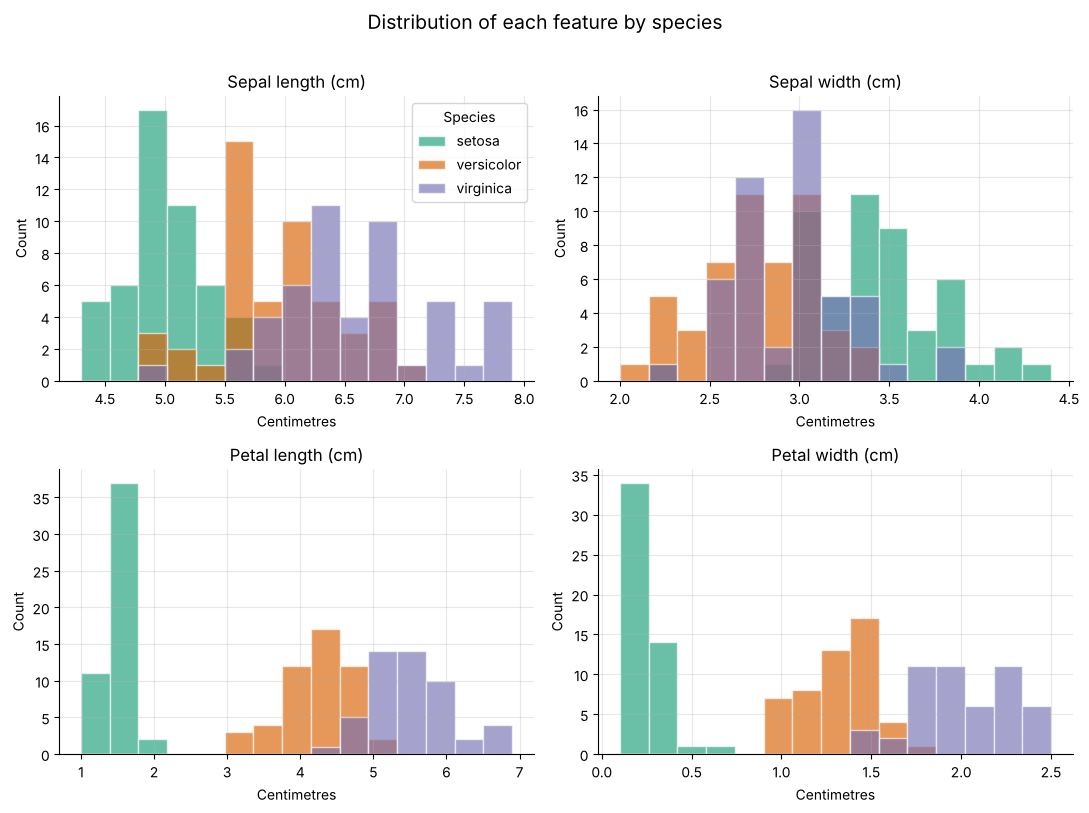

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.ravel(), FEATURES):
    bins = np.histogram_bin_edges(df[feat], bins=15)
    for sp in SPECIES:
        ax.hist(df.loc[df["species"] == sp, feat], bins=bins, alpha=0.65,
                color=COLORS[sp], label=sp, edgecolor="white")
    ax.set_title(LABELS[feat])
    ax.set_xlabel("Centimetres")
    ax.set_ylabel("Count")
axes[0, 0].legend(title="Species")
fig.suptitle("Distribution of each feature by species", fontsize=14, y=1.01)
fig.tight_layout()
fig.savefig("figures/01_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.2 Box plots
*Question: how do medians, spread and outliers compare across species?*

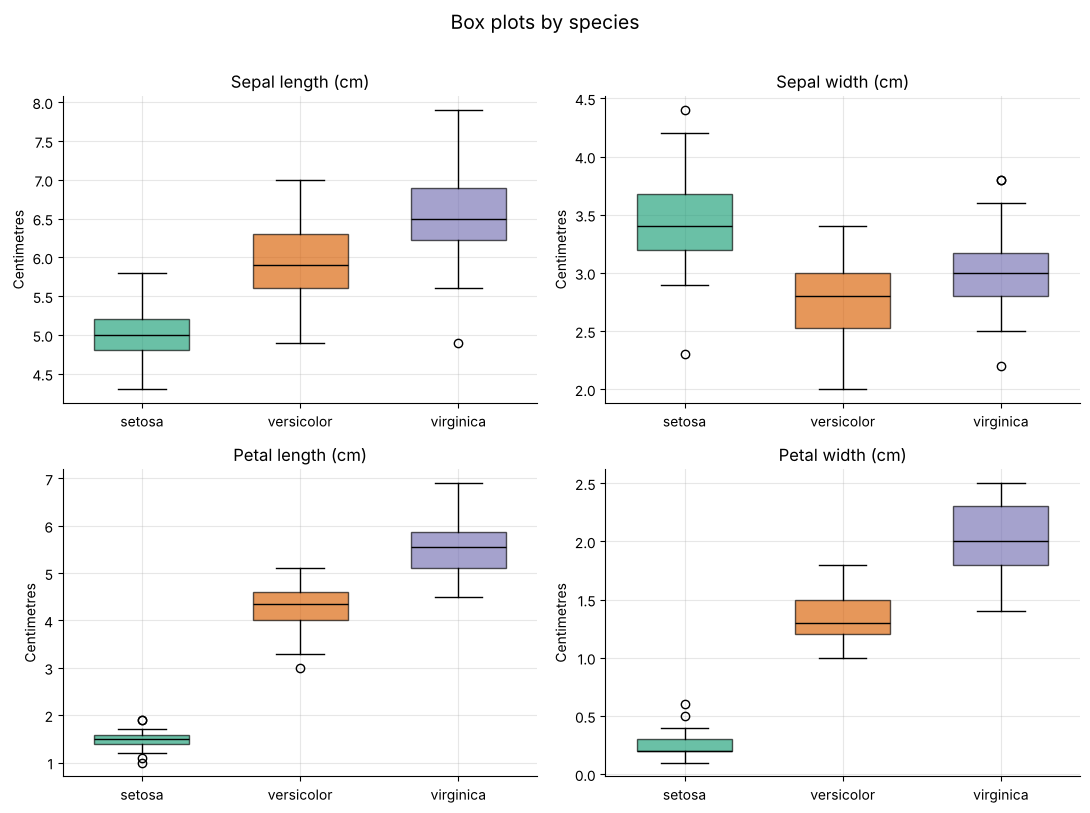

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.ravel(), FEATURES):
    data = [df.loc[df["species"] == sp, feat] for sp in SPECIES]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6)
    for patch, sp in zip(bp["boxes"], SPECIES):
        patch.set_facecolor(COLORS[sp])
        patch.set_alpha(0.65)
    for med in bp["medians"]:
        med.set_color("black")
    ax.set_xticklabels(SPECIES)
    ax.set_title(LABELS[feat])
    ax.set_ylabel("Centimetres")
fig.suptitle("Box plots by species", fontsize=14, y=1.01)
fig.tight_layout()
fig.savefig("figures/02_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.3 Violin plots
*Question: what is the full shape of each distribution (not only the quartiles)?*

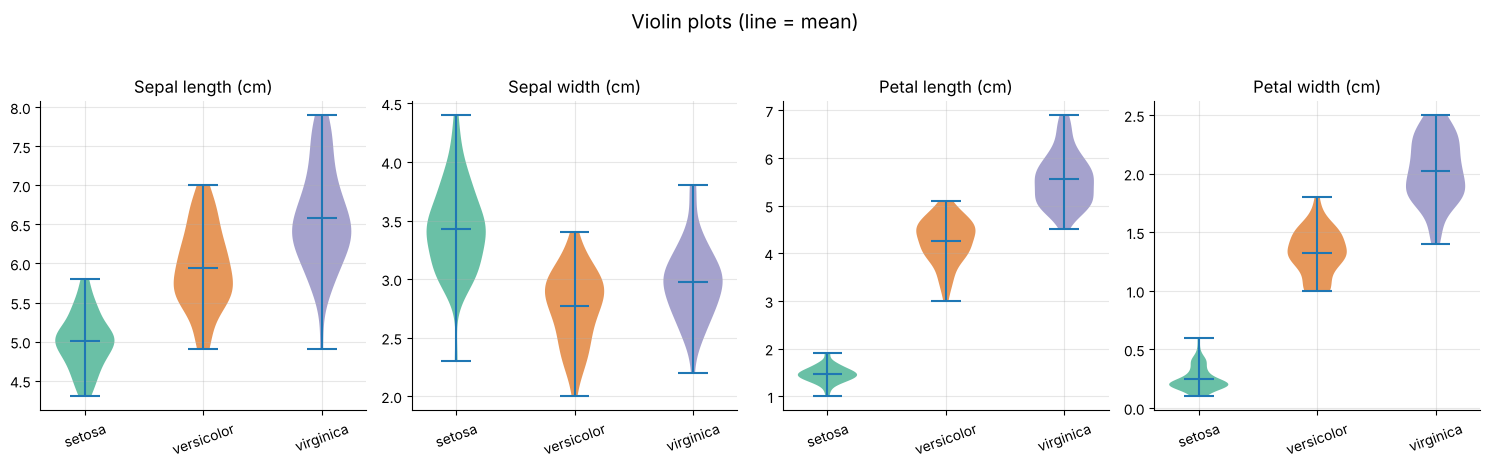

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
for ax, feat in zip(axes, FEATURES):
    data = [df.loc[df["species"] == sp, feat] for sp in SPECIES]
    parts = ax.violinplot(data, showmeans=True, showmedians=False)
    for body, sp in zip(parts["bodies"], SPECIES):
        body.set_facecolor(COLORS[sp])
        body.set_alpha(0.65)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(SPECIES, rotation=20)
    ax.set_title(LABELS[feat])
fig.suptitle("Violin plots (line = mean)", fontsize=14, y=1.03)
fig.tight_layout()
fig.savefig("figures/03_violins.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.4 Scatter plots of sepal and petal measurements
*Question: can the species be separated using two measurements?*

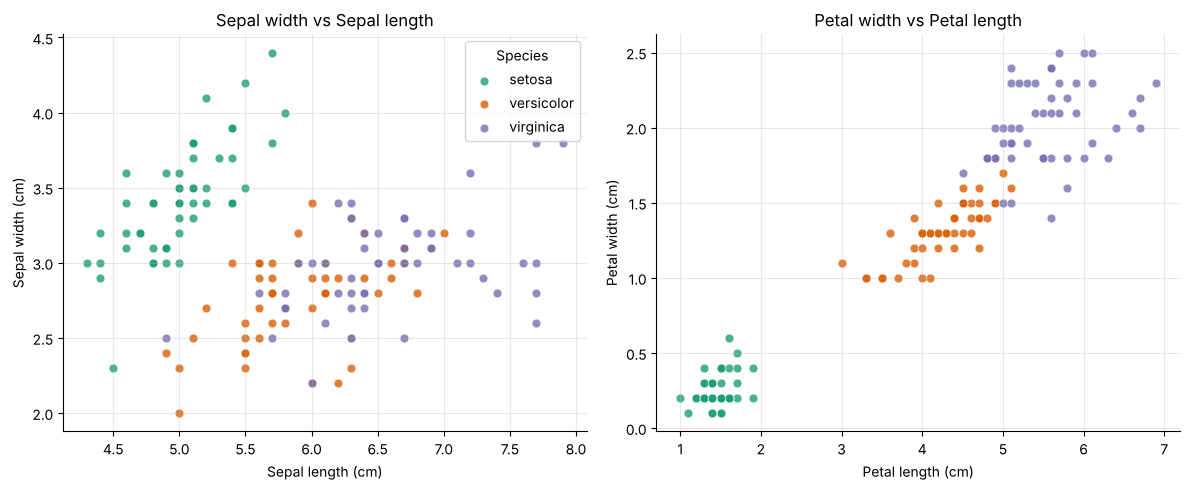

In [13]:
pairs = [("sepal_length", "sepal_width"), ("petal_length", "petal_width")]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (x, y) in zip(axes, pairs):
    for sp in SPECIES:
        g = df[df["species"] == sp]
        ax.scatter(g[x], g[y], s=40, alpha=0.8, color=COLORS[sp], label=sp,
                   edgecolor="white", linewidth=0.5)
    ax.set_xlabel(LABELS[x])
    ax.set_ylabel(LABELS[y])
    ax.set_title(f"{LABELS[y].split(' (')[0]} vs {LABELS[x].split(' (')[0]}")
axes[0].legend(title="Species")
fig.tight_layout()
fig.savefig("figures/04_scatter_sepal_petal.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.5 Scatter-plot matrix
*Question: how do all pairs of features relate to each other?*

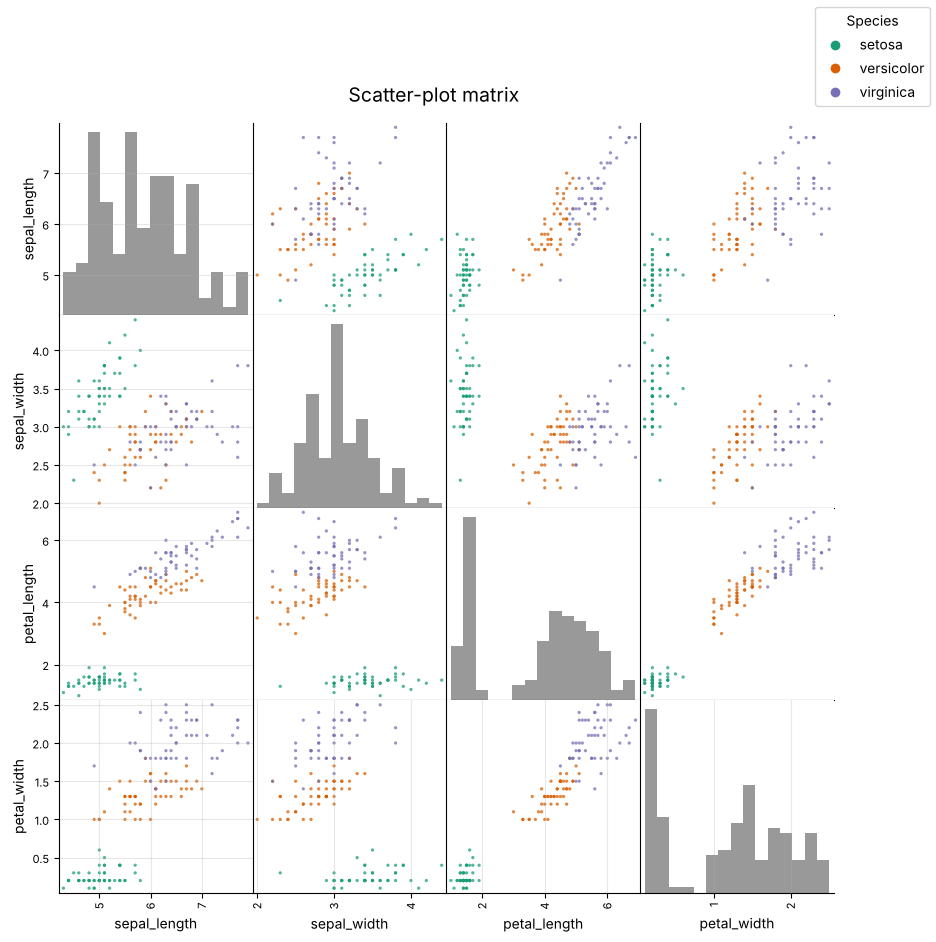

In [14]:
from pandas.plotting import scatter_matrix
from matplotlib.lines import Line2D

axarr = scatter_matrix(df[FEATURES], c=df["species"].map(COLORS), figsize=(10, 10),
                       diagonal="hist", alpha=0.75, s=22, hist_kwds={"bins": 15, "color": "#999999"})
fig = plt.gcf()
handles = [Line2D([0], [0], marker="o", linestyle="", color=COLORS[sp], label=sp) for sp in SPECIES]
fig.legend(handles=handles, title="Species", loc="upper right")
fig.suptitle("Scatter-plot matrix", fontsize=14, y=0.92)
fig.savefig("figures/05_scatter_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.6 Correlation heatmap
*Question: which features carry redundant information?*

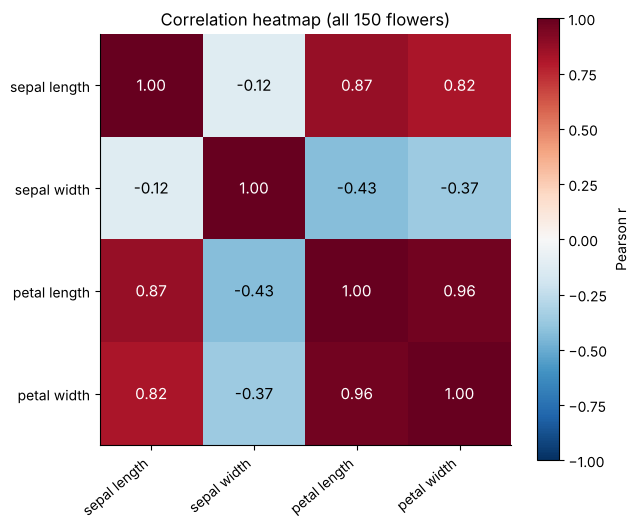

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(pearson.values, cmap="RdBu_r", vmin=-1, vmax=1)
names = [f.replace("_", " ") for f in FEATURES]
ax.set_xticks(range(4))
ax.set_xticklabels(names, rotation=40, ha="right")
ax.set_yticks(range(4))
ax.set_yticklabels(names)
ax.grid(False)
for i in range(4):
    for j in range(4):
        v = pearson.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color="white" if abs(v) > 0.6 else "black", fontsize=11)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Correlation heatmap (all 150 flowers)")
fig.tight_layout()
fig.savefig("figures/06_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Inferential statistics

The main question is: **do the three species differ in their mean measurements?** The workflow is:

1. Check the assumptions of ANOVA (normality within groups and equal variances).
2. Test overall group differences (one-way ANOVA, with the non-parametric Kruskal-Wallis test as a robustness check) and report effect sizes.
3. Run post-hoc pairwise comparisons (Tukey HSD) to see which species differ.
4. Estimate uncertainty with 95% confidence intervals.
5. Test and model the relationship between petal length and petal width.

Significance level: $\alpha = 0.05$.

### 5.1 Normality within each species (Shapiro-Wilk)
- H0: the data in the group come from a normal distribution.
- Small samples (n = 50 per group) make the test sensitive, so it is read together with the plots above.

In [16]:
rows = []
for sp in SPECIES:
    for feat in FEATURES:
        w, p = stats.shapiro(df.loc[df["species"] == sp, feat])
        rows.append({"species": sp, "feature": feat, "W": w, "p_value": p})
normality = pd.DataFrame(rows)

normality_p = normality.pivot(index="species", columns="feature", values="p_value")[FEATURES]
print(f"Shapiro-Wilk p-values (values below {ALPHA} suggest departure from normality)")
display(normality_p.round(4))
print(f"{(normality['p_value'] < ALPHA).sum()} of {len(normality)} species-feature combinations reject normality at alpha = {ALPHA}.")

Shapiro-Wilk p-values (values below 0.05 suggest departure from normality)


feature,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,0.4595,0.2715,0.0548,0.0000
versicolor,0.4647,0.3380,0.1585,0.0273
virginica,0.2583,0.1809,0.1098,0.0870


2 of 12 species-feature combinations reject normality at alpha = 0.05.


### 5.2 Homogeneity of variances (Levene / Brown-Forsythe)
- H0: all species have equal variance.
- The median-centred version is used because it is robust to non-normality.

In [17]:
rows = []
for feat in FEATURES:
    groups = [df.loc[df["species"] == sp, feat] for sp in SPECIES]
    stat, p = stats.levene(*groups, center="median")
    rows.append({"feature": feat, "Levene W": stat, "p_value": p,
                 "equal variances?": "yes" if p >= ALPHA else "no"})
pd.DataFrame(rows).round(4)

,feature,Levene W,p_value,equal variances?
0,sepal_length,6.3527,0.0023,no
1,sepal_width,0.5902,0.5555,yes
2,petal_length,19.4803,0.0000,no
3,petal_width,19.8924,0.0000,no


### 5.3 Do the species differ? One-way ANOVA and Kruskal-Wallis
- H0: all three species have the same mean (ANOVA) / the same distribution (Kruskal-Wallis).
- **Eta-squared** ($\eta^2$ = between-group sum of squares / total sum of squares) is the share of variance explained by species. Conventional benchmarks: 0.01 small, 0.06 medium, 0.14 large.
- Because the variances are not equal for every feature (5.2) and some groups depart from normality (5.1), the rank-based Kruskal-Wallis test is reported alongside ANOVA.

In [18]:
rows = []
for feat in FEATURES:
    groups = [df.loc[df["species"] == sp, feat] for sp in SPECIES]
    F, p_anova = stats.f_oneway(*groups)
    H, p_kw = stats.kruskal(*groups)
    grand = df[feat].mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_total = ((df[feat] - grand) ** 2).sum()
    rows.append({"feature": feat, "F": F, "p (ANOVA)": p_anova,
                 "eta_squared": ss_between / ss_total,
                 "H (Kruskal)": H, "p (Kruskal)": p_kw})

anova = pd.DataFrame(rows)
anova_display = anova.copy()
anova_display[["F", "H (Kruskal)"]] = anova_display[["F", "H (Kruskal)"]].round(2)
anova_display["eta_squared"] = anova_display["eta_squared"].round(3)
for col in ("p (ANOVA)", "p (Kruskal)"):
    anova_display[col] = anova_display[col].map("{:.2e}".format)
anova_display

,feature,F,p (ANOVA),eta_squared,H (Kruskal),p (Kruskal)
0,sepal_length,119.26,1.67e-31,0.619,96.94,8.92e-22
1,sepal_width,49.16,4.49e-17,0.401,63.57,1.57e-14
2,petal_length,1180.16,2.86e-91,0.941,130.41,4.80e-29
3,petal_width,960.01,4.17e-85,0.929,131.19,3.26e-29


### 5.4 Which species differ? Tukey HSD post-hoc test
Tukey's test compares all pairs of species while controlling the family-wise error rate. The table gives the mean difference, its 95% confidence interval and the adjusted p-value.

In [19]:
pair_idx = [(0, 1), (0, 2), (1, 2)]
rows = []
for feat in FEATURES:
    groups = [df.loc[df["species"] == sp, feat] for sp in SPECIES]
    res = stats.tukey_hsd(*groups)
    ci = res.confidence_interval(confidence_level=0.95)
    for i, j in pair_idx:
        rows.append({
            "feature": feat,
            "comparison": f"{SPECIES[j]} - {SPECIES[i]}",
            "mean_diff": res.statistic[j, i],
            "CI_low": ci.low[j, i],
            "CI_high": ci.high[j, i],
            "p_adj": res.pvalue[j, i],
        })

tukey = pd.DataFrame(rows)
tukey["significant"] = np.where(tukey["p_adj"] < ALPHA, "yes", "no")
tukey_display = tukey.copy()
tukey_display[["mean_diff", "CI_low", "CI_high"]] = tukey_display[["mean_diff", "CI_low", "CI_high"]].round(3)
tukey_display["p_adj"] = tukey_display["p_adj"].map("{:.2e}".format)
tukey_display

,feature,comparison,mean_diff,CI_low,CI_high,p_adj,significant
0,sepal_length,versicolor - setosa,0.930,0.686,1.174,2.42e-14,yes
1,sepal_length,virginica - setosa,1.582,1.338,1.826,2.15e-14,yes
2,sepal_length,virginica - versicolor,0.652,0.408,0.896,8.29e-09,yes
3,sepal_width,versicolor - setosa,-0.658,-0.819,-0.497,2.15e-14,yes
4,sepal_width,virginica - setosa,-0.454,-0.615,-0.293,1.36e-09,yes
5,sepal_width,virginica - versicolor,0.204,0.043,0.365,8.78e-03,yes
6,petal_length,versicolor - setosa,2.798,2.594,3.002,2.15e-14,yes
7,petal_length,virginica - setosa,4.090,3.886,4.294,2.15e-14,yes
8,petal_length,virginica - versicolor,1.292,1.088,1.496,2.15e-14,yes
9,petal_width,versicolor - setosa,1.080,0.983,1.177,2.15e-14,yes


### 5.5 The hardest pair: *versicolor* vs *virginica* (two-sample tests)
These two species overlap the most, so they are a stricter test. For each feature the cell reports:
- **Welch's t-test** (does not assume equal variances),
- the **Mann-Whitney U test** (non-parametric alternative),
- **Cohen's d** (standardised effect size: 0.2 small, 0.5 medium, 0.8 large).

In [20]:
a = df[df["species"] == "versicolor"]
b = df[df["species"] == "virginica"]

rows = []
for feat in FEATURES:
    x, y = a[feat], b[feat]
    t, p_t = stats.ttest_ind(x, y, equal_var=False)
    u, p_u = stats.mannwhitneyu(x, y, alternative="two-sided")
    pooled_sd = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
    d = (x.mean() - y.mean()) / pooled_sd
    rows.append({"feature": feat,
                 "mean versicolor": x.mean(), "mean virginica": y.mean(),
                 "Welch t": t, "p (Welch)": p_t,
                 "p (Mann-Whitney)": p_u, "Cohen's d": d})

two_sample = pd.DataFrame(rows)
two_sample_display = two_sample.copy()
for col in ("mean versicolor", "mean virginica", "Welch t", "Cohen's d"):
    two_sample_display[col] = two_sample_display[col].round(3)
for col in ("p (Welch)", "p (Mann-Whitney)"):
    two_sample_display[col] = two_sample_display[col].map("{:.2e}".format)
two_sample_display

,feature,mean versicolor,mean virginica,Welch t,p (Welch),p (Mann-Whitney),Cohen's d
0,sepal_length,5.936,6.588,-5.629,1.87e-07,5.87e-07,-1.126
1,sepal_width,2.770,2.974,-3.206,1.82e-03,4.57e-03,-0.641
2,petal_length,4.260,5.552,-12.604,4.90e-22,9.13e-17,-2.521
3,petal_width,1.326,2.026,-14.625,2.11e-25,9.70e-17,-2.925


### 5.6 95% confidence intervals for the species means
Confidence intervals use the t-distribution: $\bar{x} \pm t_{0.975,\,n-1} \cdot s/\sqrt{n}$.

In [21]:
rows = []
for sp in SPECIES:
    for feat in FEATURES:
        g = df.loc[df["species"] == sp, feat]
        n = len(g)
        half = stats.sem(g) * stats.t.ppf(0.975, n - 1)
        rows.append({"species": sp, "feature": feat, "mean": g.mean(),
                     "CI_low": g.mean() - half, "CI_high": g.mean() + half})
ci_table = pd.DataFrame(rows)
ci_table.round(3)

,species,feature,mean,CI_low,CI_high
0,setosa,sepal_length,5.006,4.906,5.106
1,setosa,sepal_width,3.428,3.320,3.536
2,setosa,petal_length,1.462,1.413,1.511
3,setosa,petal_width,0.246,0.216,0.276
4,versicolor,sepal_length,5.936,5.789,6.083
5,versicolor,sepal_width,2.770,2.681,2.859
6,versicolor,petal_length,4.260,4.126,4.394
7,versicolor,petal_width,1.326,1.270,1.382
8,virginica,sepal_length,6.588,6.407,6.769
9,virginica,sepal_width,2.974,2.882,3.066


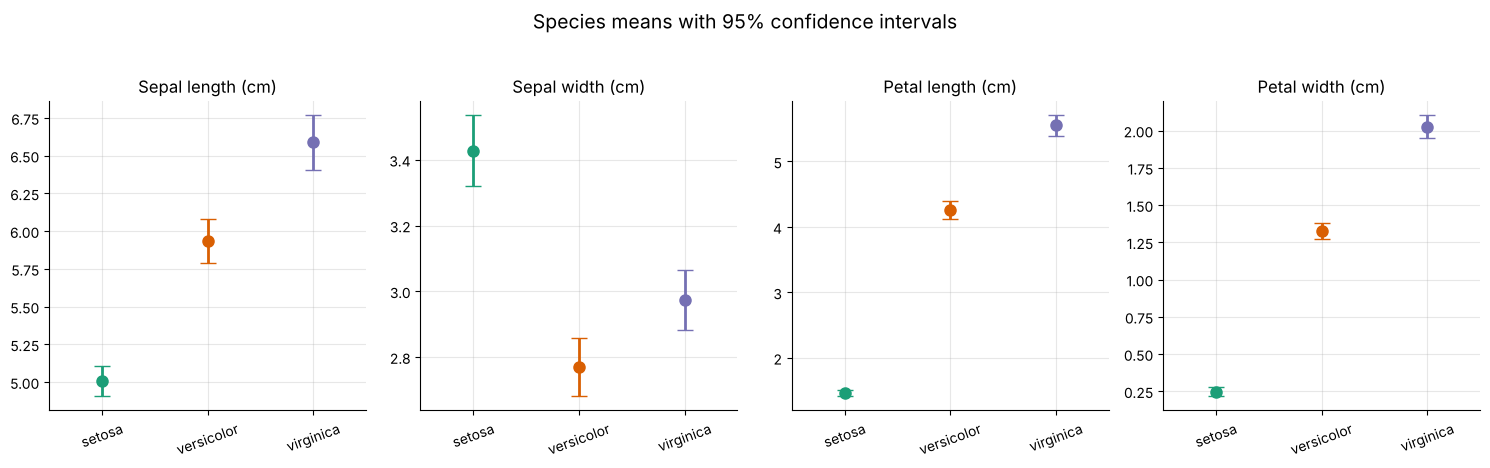

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
for ax, feat in zip(axes, FEATURES):
    sub = ci_table[ci_table["feature"] == feat].set_index("species").loc[SPECIES]
    err = [sub["mean"] - sub["CI_low"], sub["CI_high"] - sub["mean"]]
    for k, sp in enumerate(SPECIES):
        ax.errorbar(k, sub.loc[sp, "mean"],
                    yerr=[[err[0][sp]], [err[1][sp]]],
                    fmt="o", color=COLORS[sp], capsize=6, markersize=8, linewidth=2)
    ax.set_xticks(range(3))
    ax.set_xticklabels(SPECIES, rotation=20)
    ax.set_xlim(-0.5, 2.5)
    ax.set_title(LABELS[feat])
fig.suptitle("Species means with 95% confidence intervals", fontsize=14, y=1.03)
fig.tight_layout()
fig.savefig("figures/07_mean_confidence_intervals.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.7 Correlation tests: petal length vs petal width
- H0: the population correlation is zero.
- The 95% confidence interval for Pearson's r comes from the Fisher z-transformation.
- Computing the correlation **within each species** shows whether the strong overall correlation is driven mainly by the differences between species.

In [23]:
r_all = stats.pearsonr(df["petal_length"], df["petal_width"])
ci_r = r_all.confidence_interval(confidence_level=0.95)
rho_all = stats.spearmanr(df["petal_length"], df["petal_width"])

print("All species pooled (n = 150)")
print(f"  Pearson r  = {r_all.statistic:.3f}  (95% CI {ci_r.low:.3f} to {ci_r.high:.3f}), p = {r_all.pvalue:.2e}")
print(f"  Spearman rho = {rho_all.statistic:.3f}, p = {rho_all.pvalue:.2e}\n")

rows = []
for sp in SPECIES:
    g = df[df["species"] == sp]
    r = stats.pearsonr(g["petal_length"], g["petal_width"])
    ci = r.confidence_interval(confidence_level=0.95)
    rows.append({"species": sp, "n": len(g), "Pearson r": r.statistic,
                 "CI_low": ci.low, "CI_high": ci.high, "p_value": f"{r.pvalue:.2e}"})
print("Within each species (n = 50)")
pd.DataFrame(rows).round(3)

All species pooled (n = 150)
  Pearson r  = 0.963  (95% CI 0.949 to 0.973), p = 4.68e-86
  Spearman rho = 0.938, p = 8.16e-70

Within each species (n = 50)


,species,n,Pearson r,CI_low,CI_high,p_value
0,setosa,50,0.332,0.059,0.558,1.86e-02
1,versicolor,50,0.787,0.651,0.874,1.27e-11
2,virginica,50,0.322,0.048,0.551,2.25e-02


### 5.8 Simple linear regression: petal width ~ petal length
A least-squares line quantifies the relationship; the residual plot checks the fit.

petal_width = -0.363 + 0.416 x petal_length
slope standard error = 0.0096
R-squared = 0.927
p-value (slope = 0) = 4.68e-86


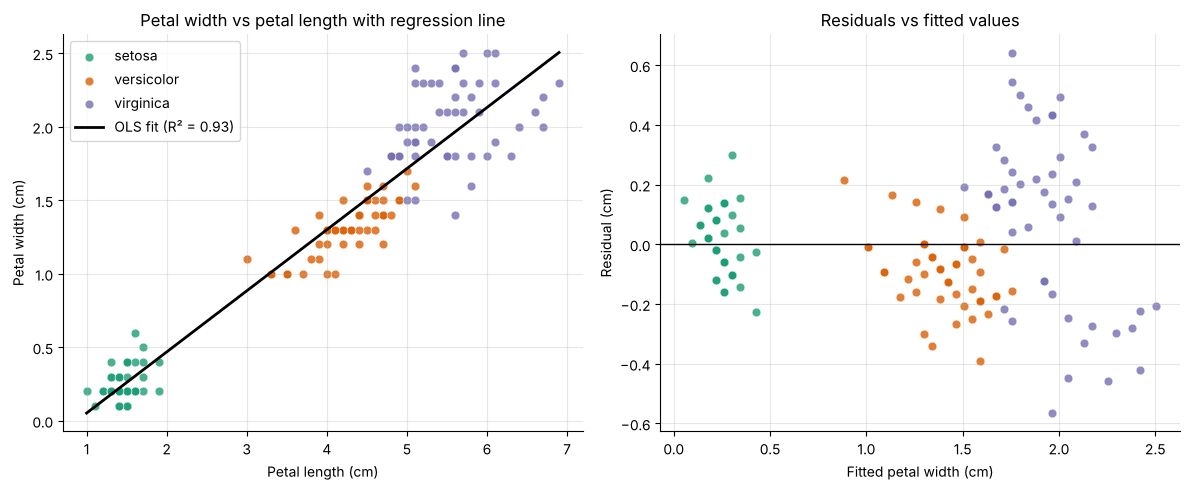

In [24]:
lr = stats.linregress(df["petal_length"], df["petal_width"])
print(f"petal_width = {lr.intercept:.3f} + {lr.slope:.3f} x petal_length")
print(f"slope standard error = {lr.stderr:.4f}")
print(f"R-squared = {lr.rvalue ** 2:.3f}")
print(f"p-value (slope = 0) = {lr.pvalue:.2e}")

fitted = lr.intercept + lr.slope * df["petal_length"]
residuals = df["petal_width"] - fitted

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
xs = np.linspace(df["petal_length"].min(), df["petal_length"].max(), 100)
for sp in SPECIES:
    g = df[df["species"] == sp]
    axes[0].scatter(g["petal_length"], g["petal_width"], s=40, alpha=0.8, color=COLORS[sp],
                    label=sp, edgecolor="white", linewidth=0.5)
axes[0].plot(xs, lr.intercept + lr.slope * xs, color="black", linewidth=2,
             label=f"OLS fit (R² = {lr.rvalue ** 2:.2f})")
axes[0].set_xlabel(LABELS["petal_length"])
axes[0].set_ylabel(LABELS["petal_width"])
axes[0].set_title("Petal width vs petal length with regression line")
axes[0].legend()

for sp in SPECIES:
    mask = df["species"] == sp
    axes[1].scatter(fitted[mask], residuals[mask], s=40, alpha=0.8, color=COLORS[sp],
                    edgecolor="white", linewidth=0.5)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Fitted petal width (cm)")
axes[1].set_ylabel("Residual (cm)")
axes[1].set_title("Residuals vs fitted values")
fig.tight_layout()
fig.savefig("figures/08_regression.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Key findings

**Data and descriptive statistics**
- The dataset is clean: 150 flowers, no missing values, 50 per species (one duplicated measurement row was kept).
- The petal measurements vary far more than the sepal measurements (CV of about 47% for petal length and 64% for petal width, versus about 14% for both sepal features) and are clearly **bimodal**, because *setosa* has tiny petals.
- Mean petal length rises from **1.46 cm (setosa)** to **4.26 cm (versicolor)** to **5.55 cm (virginica)**; mean petal width rises from 0.25 to 1.33 to 2.03 cm.

**Inferential statistics**
- **Species differ significantly on every feature** (one-way ANOVA and Kruskal-Wallis, all p < 0.001). Species explains about **94% of the variance in petal length** and **93% in petal width** ($\eta^2$), but only 62% for sepal length and 40% for sepal width.
- **Tukey HSD:** all 12 pairwise comparisons are significant. The weakest is *virginica* vs *versicolor* on sepal width (adjusted p ≈ 0.009).
- **Hardest pair (*versicolor* vs *virginica*):** the petal features separate them with very large effects (Cohen's d about -2.5 for petal length and -2.9 for petal width), whereas sepal width gives only a medium effect (d about -0.64).
- **Assumptions:** 2 of 12 group-feature combinations reject normality (petal width in setosa and versicolor), and variances are unequal for sepal length, petal length and petal width. Because the rank-based Kruskal-Wallis and Mann-Whitney tests agree with ANOVA and Welch's t-test, the conclusions do not depend on these violations.
- **Relationship between petal measurements:** petal length and width are very strongly correlated (Pearson r = 0.963, 95% CI 0.949 to 0.973). The regression `petal_width = -0.363 + 0.416 × petal_length` explains 92.7% of the variance, i.e. each extra centimetre of petal length goes with about 0.42 cm of extra width.
- **Caution:** within a single species the correlation is much weaker (r = 0.33 for setosa, 0.79 for versicolor, 0.32 for virginica). The strong pooled correlation therefore comes largely from the **differences between species**, not from a uniform relationship inside each species.

**Practical conclusion:** petal length and petal width are the most informative features for telling the species apart. *Setosa* is completely separable from the other two, while *versicolor* and *virginica* overlap slightly but are still clearly different on the petal measurements.

**Limitations**
- Many hypothesis tests were run; the Tukey procedure controls error within each feature, but the p-values across features were not corrected jointly. With p-values this small the conclusions would not change.
- The data are a classic, small, hand-measured sample (50 flowers per species), so the results describe this sample and should not be extrapolated to all irises.

## 7. Reproducibility and GitHub workflow

### 7.1 Project layout
```
iris-analysis/
├── iris_analysis.ipynb      # this notebook (analysis + narrative)
├── data/
│   └── iris.csv             # dataset used by the notebook
├── figures/                 # charts written by the notebook
├── requirements.txt         # pinned minimum package versions
├── README.md                # project description and how to run it
└── .gitignore
```

### 7.2 Run it locally
```bash
git clone https://github.com/<your-username>/iris-analysis.git
cd iris-analysis
python -m venv .venv
source .venv/bin/activate          # Windows: .venv\Scripts\activate
pip install -r requirements.txt
jupyter notebook iris_analysis.ipynb
```
Use **Kernel → Restart & Run All** to regenerate every table and figure from scratch.

### 7.3 Publish the project to GitHub
1. Create an empty repository named `iris-analysis` on github.com (no README, since one already exists locally).
2. In the project folder run:
```bash
git init
git add .
git commit -m "Add Iris descriptive and inferential analysis notebook"
git branch -M main
git remote add origin https://github.com/<your-username>/iris-analysis.git
git push -u origin main
```
3. For later changes, use small commits with clear messages:
```bash
git add -A
git commit -m "Describe what changed and why"
git push
```

### 7.4 Why this is reproducible
- **Fixed random seed** (`SEED = 42`), although the methods used here are deterministic.
- **Data is versioned** alongside the code, and the notebook can regenerate it if missing.
- **Dependencies are listed** in `requirements.txt`; the exact versions used are printed below.
- **Version control** records every change to the analysis, and GitHub renders the notebook with its outputs.

In [25]:
print(f"Python      {sys.version.split()[0]} ({platform.system()})")
print(f"NumPy       {np.__version__}")
print(f"pandas      {pd.__version__}")
print(f"SciPy       {scipy.__version__}")
print(f"Matplotlib  {matplotlib.__version__}")

Python      3.13.18 (Linux)
NumPy       2.5.3
pandas      3.0.5
SciPy       1.18.1
Matplotlib  3.11.2
